**Project Objective-**

The goal of this project is to analyze student academic data and predict their performance using machine learning models.

The project includes two prediction tasks:
1. Regression Task
2. Predict the Final Score (G3) of a student.

Classification Task-
Predict whether the student will Pass or Fail.

Machine learning algorithms used:
1. Linear Regression
2. Logistic Regression
3. Decision Tree

**Import Libraries**

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import mean_squared_error
from sklearn.metrics import accuracy_score

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

**Load Dataset**

In [4]:
df = pd.read_csv("student_data.csv")
df.head()
df.shape
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


**Data Preprocessing**

The dataset contains categorical values such as:
1. School
2. Sex
3. Address
4. Guardian
5. Internet
6. Activities

These must be converted into numerical values before training the model.

In [5]:
encoder = LabelEncoder()

for column in df.columns:
    if df[column].dtype == "object":
        df[column] = encoder.fit_transform(df[column])

df.isnull().sum()

,0
school,0
sex,0
age,0
address,0
famsize,0
Pstatus,0
Medu,0
Fedu,0
Mjob,0
Fjob,0


**Create Target Variables**

In this dataset:
G3 = Final grade of student

**Regression target:** G3

**Classification target:**

Create Pass/Fail column.

Here:

1. 1 = Pass
2. 0 = Fail

In [6]:
df["Pass_Fail"] = df["G3"].apply(lambda x: 1 if x >= 10 else 0)

**Feature Selection**

In [7]:
X = df.drop(["G3","Pass_Fail"], axis=1)

y_regression = df["G3"]
y_classification = df["Pass_Fail"]

In [8]:
y_regression

,G3
0,6
1,6
2,10
3,15
4,10
...,...
390,9
391,16
392,7
393,10


In [9]:
y_classification

,Pass_Fail
0,0
1,0
2,1
3,1
4,1
...,...
390,0
391,1
392,0
393,1


**Train-Test Split**

In [10]:
X_train, X_test, y_train_reg, y_test_reg = train_test_split(
    X, y_regression, test_size=0.2, random_state=42)

# Classification train-test split

X_train2, X_test2, y_train_clf, y_test_clf = train_test_split(
    X,
    y_classification,
    test_size=0.2,
    random_state=42,
    stratify=y_classification
)

**Linear Regression (Final Score Prediction)**

In [11]:
lr = LinearRegression()
lr.fit(X_train, y_train_reg)
pred_score = lr.predict(X_test)
X_test

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2
78,0,1,17,1,0,1,2,1,2,2,...,0,4,5,1,1,1,3,2,8,8
371,1,1,18,0,1,1,1,2,0,3,...,1,4,3,3,2,3,3,3,14,12
248,0,1,18,0,1,1,3,3,2,3,...,1,4,3,3,1,3,5,8,3,5
55,0,0,16,1,0,0,2,1,2,2,...,1,5,3,4,1,1,2,8,8,9
390,1,1,20,1,1,0,2,2,3,3,...,0,5,5,4,4,5,4,11,9,9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
364,1,0,17,0,0,1,1,2,2,3,...,0,3,2,2,1,2,3,0,12,11
82,0,0,15,1,1,1,3,2,3,2,...,0,4,4,4,1,1,5,10,7,6
114,0,1,15,0,0,1,2,1,1,3,...,1,5,4,2,1,1,5,8,9,9
3,0,0,15,1,0,1,4,2,1,3,...,1,3,2,2,1,1,5,2,15,14


**Model Evaluation**

In [12]:
mse = mean_squared_error(y_test_reg, pred_score)
print("Mean Squared Error:", mse)

Mean Squared Error: 5.03239410886674


**Logistic Regression (Pass / Fail Prediction)**

In [13]:
log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train2, y_train_clf)
pred_log = log_model.predict(X_test2)
print("Accuracy:", accuracy_score(y_test_clf, pred_log))

# Logistic Regression Evaluation

print("Logistic Regression Evaluation")

print("Accuracy:",
      accuracy_score(y_test_clf, pred_log))

print("Precision:",
      precision_score(
          y_test_clf, pred_log,
          zero_division=0
      ))

print("Recall:",
      recall_score(
          y_test_clf, pred_log,
          zero_division=0
      ))

print("F1 Score:",
      f1_score(
          y_test_clf, pred_log,
          zero_division=0
      ))

print("\nClassification Report:")

print(
    classification_report(
        y_test_clf,
        pred_log,
        target_names=['Fail', 'Pass'],
        zero_division=0
    )
)

Accuracy: 0.8607594936708861
Logistic Regression Evaluation
Accuracy: 0.8607594936708861
Precision: 0.9565217391304348
Recall: 0.8301886792452831
F1 Score: 0.8888888888888888

Classification Report:
              precision    recall  f1-score   support

        Fail       0.73      0.92      0.81        26
        Pass       0.96      0.83      0.89        53

    accuracy                           0.86        79
   macro avg       0.84      0.88      0.85        79
weighted avg       0.88      0.86      0.86        79



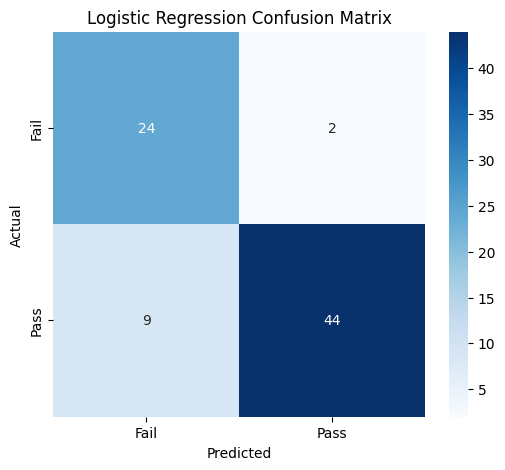

In [14]:
# Logistic Regression Confusion Matrix

cm_log = confusion_matrix(
    y_test_clf,
    pred_log,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_log,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Fail', 'Pass'],
    yticklabels=['Fail', 'Pass']
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

**Decision Tree Model**

In [15]:
tree = DecisionTreeClassifier()
tree.fit(X_train2, y_train_clf)
pred_tree = tree.predict(X_test2)
print("Decision Tree Accuracy:", accuracy_score(y_test_clf, pred_tree))

# Decision Tree Evaluation

print("Decision Tree Evaluation")

print("Accuracy:",
      accuracy_score(y_test_clf, pred_tree))

print("Precision:",
      precision_score(
          y_test_clf, pred_tree,
          zero_division=0
      ))

print("Recall:",
      recall_score(
          y_test_clf, pred_tree,
          zero_division=0
      ))

print("F1 Score:",
      f1_score(
          y_test_clf, pred_tree,
          zero_division=0
      ))

print("\nClassification Report:")

print(
    classification_report(
        y_test_clf,
        pred_tree,
        target_names=['Fail', 'Pass'],
        zero_division=0
    )
)

Decision Tree Accuracy: 0.8481012658227848
Decision Tree Evaluation
Accuracy: 0.8481012658227848
Precision: 0.9361702127659575
Recall: 0.8301886792452831
F1 Score: 0.88

Classification Report:
              precision    recall  f1-score   support

        Fail       0.72      0.88      0.79        26
        Pass       0.94      0.83      0.88        53

    accuracy                           0.85        79
   macro avg       0.83      0.86      0.84        79
weighted avg       0.86      0.85      0.85        79



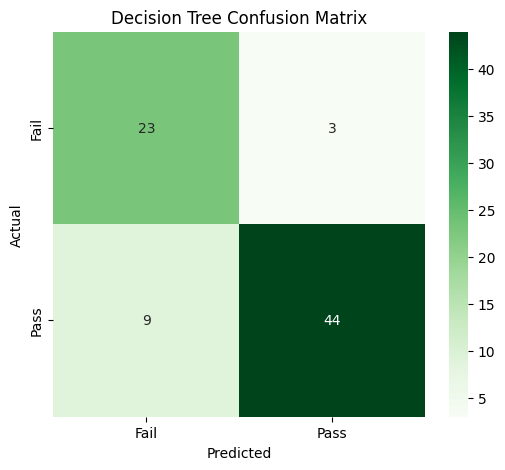

In [16]:
# Decision Tree Confusion Matrix

cm_tree = confusion_matrix(
    y_test_clf,
    pred_tree,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_tree,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Fail', 'Pass'],
    yticklabels=['Fail', 'Pass']
)

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [17]:
# Compare model performance

model_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree'
    ],

    'Accuracy': [
        accuracy_score(y_test_clf, pred_log),
        accuracy_score(y_test_clf, pred_tree)
    ],

    'Precision': [
        precision_score(y_test_clf, pred_log,
                        zero_division=0),
        precision_score(y_test_clf, pred_tree,
                        zero_division=0)
    ],

    'Recall': [
        recall_score(y_test_clf, pred_log,
                     zero_division=0),
        recall_score(y_test_clf, pred_tree,
                     zero_division=0)
    ],

    'F1 Score': [
        f1_score(y_test_clf, pred_log,
                 zero_division=0),
        f1_score(y_test_clf, pred_tree,
                 zero_division=0)
    ]
})

display(model_comparison)

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.860759,0.956522,0.830189,0.888889
1,Decision Tree,0.848101,0.936170,0.830189,0.880000


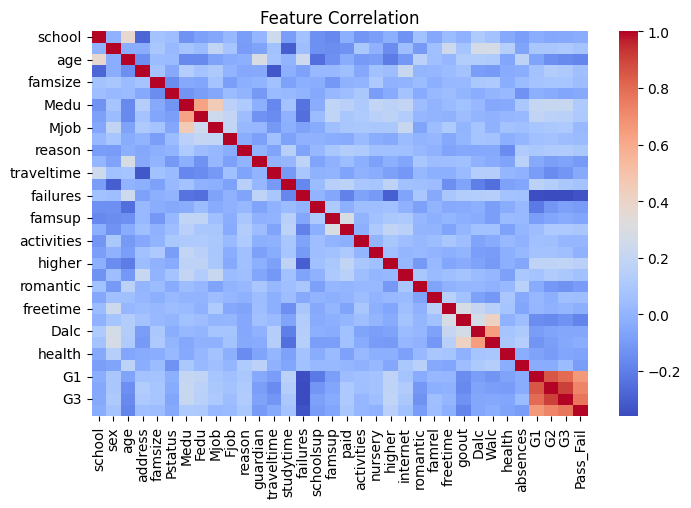

In [18]:
plt.figure(figsize=(8,5))
sns.heatmap(df.corr(), cmap="coolwarm")
plt.title("Feature Correlation")
plt.show()

**Final Output**
| Prediction Type | Model                               |
| --------------- | ----------------------------------- |
| Final Score     | Linear Regression                   |
| Pass / Fail     | Logistic Regression / Decision Tree |


| Student   | Predicted Score | Result |
| --------- | --------------- | ------ |
| Student A |   14              | Pass   |
| Student B |   8               | Fail   |
